In [1]:
%autosave 60

Autosaving every 60 seconds


In [2]:
print(1)

1


## Подготовка

In [3]:
import os
from pathlib import Path
from scipy import stats
import matplotlib.colors as mcolors

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

NOTEBOOK_DIR = Path(".").resolve()
STYLE_PATH = NOTEBOOK_DIR / "presentation.mplstyle"
plt.style.use(str(STYLE_PATH))

In [4]:
image_name_prefix = 'Широкова Соня'

path_to_save_images = NOTEBOOK_DIR / 'images'

path_to_data = NOTEBOOK_DIR / 'data'
train_csv = path_to_data / 'train.csv'

In [5]:
path_to_data.mkdir(parents=True, exist_ok=True)
os.makedirs(path_to_save_images, exist_ok=True)

In [6]:
if not train_csv.exists():
    raise FileNotFoundError(
        f"Файл не найден: {train_csv}\n"
        "Скачайте train.csv с Kaggle и положите в папку data/"
    )

df = pd.read_csv(train_csv)
target_col = 'SalePrice'
y = df[target_col]
feature_names = [c for c in df.columns if c != target_col and c != 'Id']

print(f'Загружено строк: {len(df)}, признаков: {len(feature_names)}')
df.head()

Загружено строк: 1460, признаков: 79


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## line plot

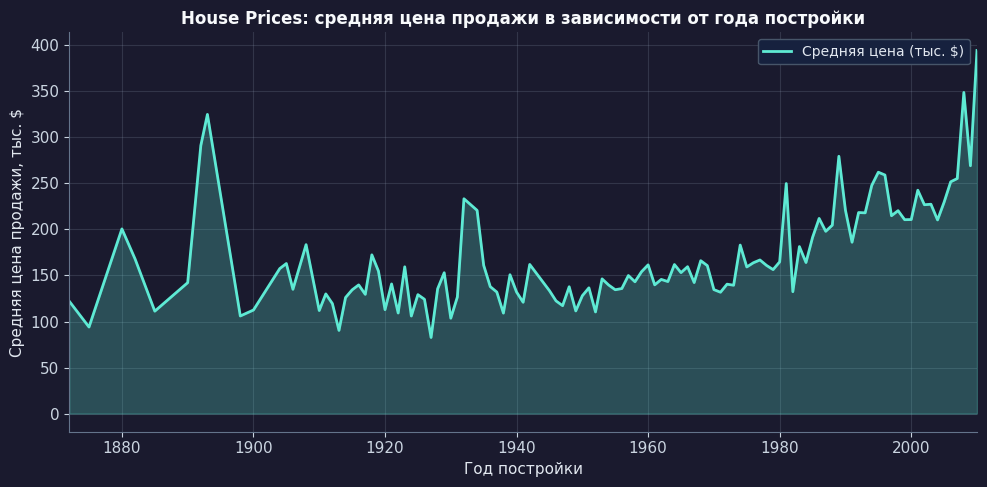

In [7]:
by_year = df.groupby('YearBuilt', as_index=False).agg(
    mean_price=('SalePrice', 'mean'),
    count=('SalePrice', 'count')
).sort_values('YearBuilt')

fig, ax = plt.subplots(figsize=(10, 5), facecolor='#1a1a2e')
ax.set_facecolor('#1a1a2e')

ax.plot(by_year['YearBuilt'], by_year['mean_price'] / 1000, color='#5eead4', linewidth=2, label='Средняя цена (тыс. $)')
ax.fill_between(by_year['YearBuilt'], by_year['mean_price'] / 1000, alpha=0.25, color='#5eead4')
ax.set_xlabel('Год постройки', color='#e2e8f0', fontsize=11)
ax.set_ylabel('Средняя цена продажи, тыс. $', color='#e2e8f0', fontsize=11)
ax.set_title('House Prices: средняя цена продажи в зависимости от года постройки', color='#f8fafc', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', facecolor='#16213e', edgecolor='#475569', labelcolor='#e2e8f0', fontsize=10)
ax.set_xlim(by_year['YearBuilt'].min(), by_year['YearBuilt'].max())
ax.tick_params(axis='both', colors='#cbd5e1', labelsize=11)
ax.spines['bottom'].set_color('#64748b')
ax.spines['left'].set_color('#64748b')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, alpha=0.2, color='#94a3b8')
ax.set_axisbelow(True)
fig.tight_layout()

plt.savefig(
    os.path.join(path_to_save_images, f'{image_name_prefix}_image_1.png'),
    dpi=100,
    bbox_inches='tight',
    facecolor='#1a1a2e',
    edgecolor='none'
)
plt.show()

#### Выводы

На графике видно, что средняя цена продажи растёт с годом постройки: дома, построенные в 2000‑х, в среднем продаются дороже, чем дома 1960–80‑х. Сильные колебания в старых годах (до ~1900) связаны с малым числом наблюдений в этих годах. Год постройки можно рассматривать как один из предикторов цены при дальнейшем моделировании.

## bar plot или stacked bar plot

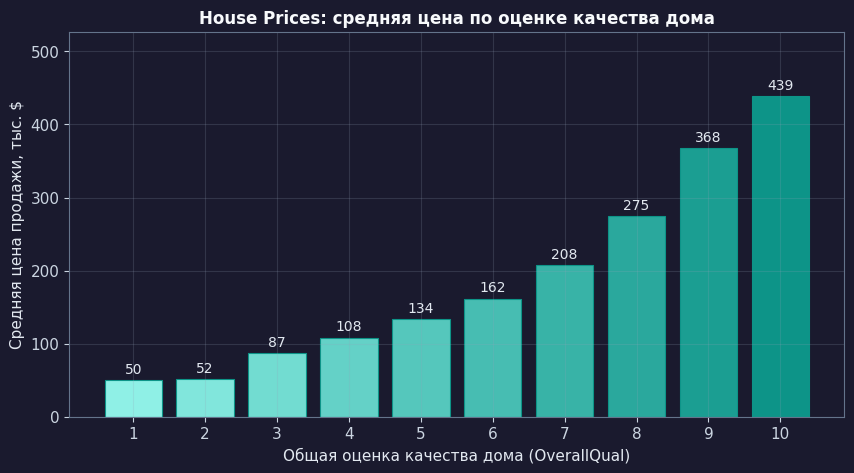

In [8]:
by_qual = df.groupby('OverallQual', as_index=False).agg(
    mean_price=('SalePrice', 'mean')
)
by_qual['mean_price_k'] = by_qual['mean_price'] / 1000

import matplotlib.colors as mcolors

cmap = mcolors.LinearSegmentedColormap.from_list(
    'cyan_grad',
    ['#8ff0e6', '#0d9488'], 
    N=len(by_qual)
)
colors = [mcolors.to_hex(cmap(i / (len(by_qual) - 1))) for i in range(len(by_qual))]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    by_qual['OverallQual'].astype(str),
    by_qual['mean_price_k'],
    color=colors,
    edgecolor='#0d9488',
    linewidth=0.8
)

for bar, val in zip(bars, by_qual['mean_price_k']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f'{val:.0f}',
        ha='center',
        va='bottom',
        fontsize=10,
        color='#e2e8f0'
    )

ax.set_xlabel('Общая оценка качества дома (OverallQual)')
ax.set_ylabel('Средняя цена продажи, тыс. $')
ax.set_title('House Prices: средняя цена по оценке качества дома')
ax.set_ylim(0, by_qual['mean_price_k'].max() * 1.2)

plt.savefig(
    os.path.join(path_to_save_images, f'{image_name_prefix}_image_2.png'),
    dpi=100,
    bbox_inches='tight'
)
plt.show()

#### Выводы
График показывает сильную связь между общей оценкой качества дома (OverallQual) и средней ценой продажи: с ростом оценки с 1 до 10 средняя цена монотонно увеличивается (от ~50 до ~430 тыс. долларов). Рост ускоряется на высоких оценках (7–10): разница в цене между соседними уровнями качества там больше. OverallQual — один из самых важных предикторов цены и его стоит учитывать в модели.

##  hist plot или pair plot или kde plot

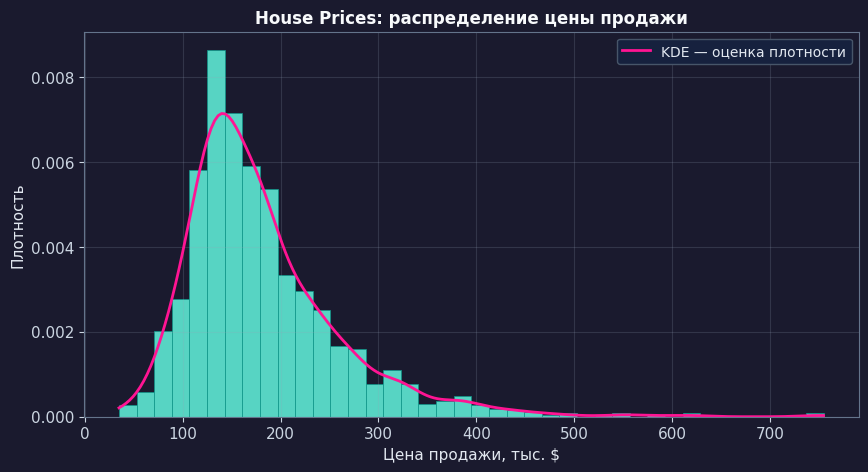

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

price_k = df['SalePrice'] / 1000

sns.histplot(
    price_k,
    bins=40,
    kde=False,
    stat='density',
    color='#5eead4',
    edgecolor='#0d9488',
    linewidth=0.5,
    alpha=0.9,
    ax=ax
)

x_range = np.linspace(price_k.min(), price_k.max(), 200)
kde = stats.gaussian_kde(price_k)
ax.plot(x_range, kde(x_range), color='#ff1493', linewidth=2, label='KDE — оценка плотности')
ax.legend(loc='upper right')

ax.set_xlabel('Цена продажи, тыс. $')
ax.set_ylabel('Плотность')
ax.set_title('House Prices: распределение цены продажи')

plt.savefig(
    os.path.join(path_to_save_images, f'{image_name_prefix}_image_3.png'),
    dpi=100,
    bbox_inches='tight'
)
plt.show()

#### Выводы
Распределение цены продажи правостороннее: большинство домов продаётся в диапазоне примерно 100–200 тыс.,
пикплотности—около 150 – 160 тыс. Высокие цены (выше 300–400 тыс. долларов) встречаются реже, длинный правый хвост говорит о выбросах или более дорогом сегменте. KDE повторяет эту форму и подходит для использования цены как целевой переменной в регрессии. При моделировании имеет смысл рассмотреть логарифмирование цены или отсечение выбросов.

## heatmap plot

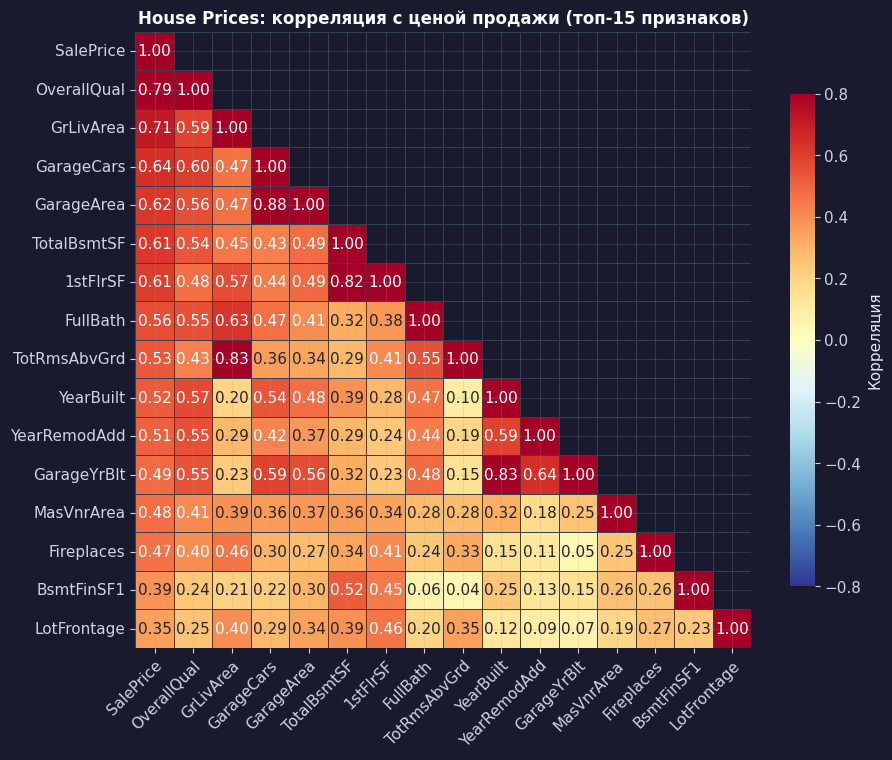

In [10]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_full = df[numeric_cols].corr()

sale_corr = corr_full['SalePrice'].drop('SalePrice').abs().nlargest(15)
cols = ['SalePrice'] + sale_corr.index.tolist()
corr = df[cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    center=0,
    vmin=-0.8,
    vmax=0.8,
    square=True,
    linewidths=0.5,
    linecolor='#334155',
    cbar_kws=dict(label='Корреляция', shrink=0.8),
    ax=ax
)

ax.set_title('House Prices: корреляция с ценой продажи (топ-15 признаков)')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

plt.savefig(
    os.path.join(path_to_save_images, f'{image_name_prefix}_image_4.png'),
    dpi=100,
    bbox_inches='tight'
)
plt.show()

#### Выводы

Сильнее всего с ценой продажи связаны OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64), GarageArea (0.62), TotalBsmtSF и 1stFlrSF (по 0.61) — их стоит рассматривать как основные предикторы. Между признаками есть сильная корреляция (например, GarageCars и GarageArea — 0.88, TotalBsmtSF и 1stFlrSF — 0.82), поэтому при отборе признаков или регуляризации нужно учитывать мультиколлинеарность. Heatmap подтверждает, что для предсказания цены разумно опираться на качество, площадь и характеристики гаража и подвала; при построении регрессии часть сильно связанных признаков можно объединить или отбросить, чтобы упростить модель.

##  box plot

/var/folders/xb/xmkb2ry17s75qvkmwc430v3c0000gq/T/ipykernel_64885/2393598567.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


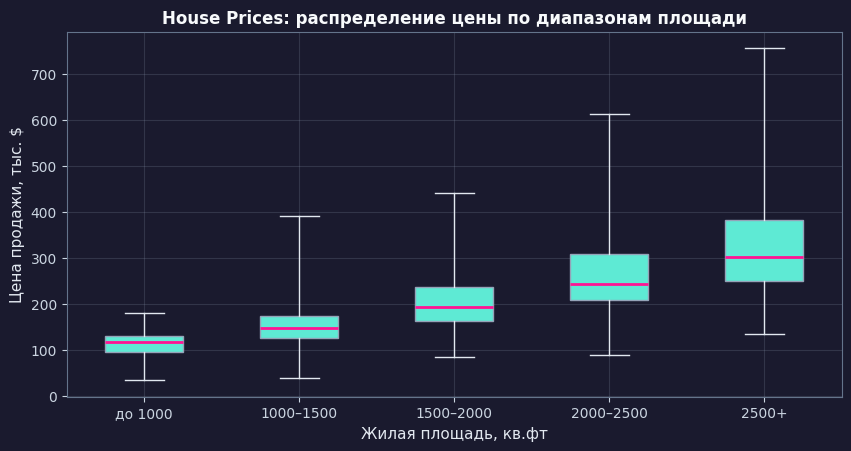

In [11]:
df_plot = df.copy()
df_plot['GrLivArea_bin'] = pd.cut(
    df_plot['GrLivArea'],
    bins=[0, 1000, 1500, 2000, 2500, 6000],
    labels=['до 1000', '1000–1500', '1500–2000', '2000–2500', '2500+']
)
df_plot['SalePrice_k'] = df_plot['SalePrice'] / 1000

fig, ax = plt.subplots(figsize=(10, 5))

bp = ax.boxplot(
    [df_plot.loc[df_plot['GrLivArea_bin'] == b, 'SalePrice_k'].dropna()
     for b in df_plot['GrLivArea_bin'].cat.categories],
    labels=df_plot['GrLivArea_bin'].cat.categories.tolist(),
    patch_artist=True,
    whis=(0, 100),  # усы до min/max
    medianprops=dict(color='#ff1493', linewidth=2),
    boxprops=dict(facecolor='#5eead4', edgecolor='#94a3b8', linewidth=1),
    whiskerprops=dict(color='#e2e8f0', linewidth=1),
    capprops=dict(color='#e2e8f0', linewidth=1),
    flierprops=dict(marker='o', markersize=4, alpha=0.5, color='#94a3b8')
)

ax.set_xlabel('Жилая площадь, кв.фт')
ax.set_ylabel('Цена продажи, тыс. $')
ax.set_title('House Prices: распределение цены по диапазонам площади')
ax.tick_params(axis='both', labelsize=10)
ax.yaxis.grid(True, alpha=0.2)
ax.set_axisbelow(True)

fig.subplots_adjust(bottom=0.15)

plt.savefig(
    os.path.join(path_to_save_images, f'{image_name_prefix}_image_5.png'),
    dpi=100,
    bbox_inches='tight'
)
plt.show()

#### Выводы

По графику видно, что с ростом жилой площади растёт и медианная цена продажи: от ~125 тыс. долларов для площади до 1000 кв.фт до ~310 тыс. долларов для категории 2500+ кв.фт. Разброс цен также увеличивается с площадью — у категории «2500+» самый широкий диапазон (от ~130 до ~750 тыс. долларов). Связь площадь–цена подтверждается как по медианам, так и по межквартильному размаху; GrLivArea можно использовать как важный предиктор в модели.

# Итоговый вывод по всему датасету

Целевая переменная (SalePrice). 

Распределение цены продажи правостороннее: большинство сделок сосредоточено в диапазоне 100–250 тыс. долларов при моде около 150–170 тыс. долларов. Наличие длинного правого хвоста указывает на выбросы и дорогой сегмент; для регрессии целесообразно рассмотреть логарифмирование цены или ограничение выбросов.

Ключевые предикторы. 

Сильнее всего с ценой связаны общая оценка качества (OverallQual, корреляция ~0.79), жилая площадь (GrLivArea, ~0.71), характеристики гаража (GarageCars, GarageArea) и подвала (TotalBsmtSF, 1stFlrSF). Столбчатая диаграмма по OverallQual подтверждает устойчивый рост средней цены с повышением качества (от ~50 до ~439 тыс. долларов) с ускорением на высоких оценках. Эти признаки следует рассматривать как основные при отборе переменных для модели.

Связь с годом постройки и площадью. 

Линейный график по году постройки показывает рост средней цены к более новым домам (особенно с 1980-х годов), с высокой волатильностью в старых годах из‑за малого числа наблюдений. Box plot по диапазонам жилой площади демонстрирует рост медианной цены от ~125 тыс. долларов (до 1000 кв.фт) до ~305 тыс. долларов (2500+ кв.фт) и увеличение разброса цен с ростом площади.

Мультиколлинеарность. 

Тепловая карта корреляций выявляет сильные связи между признаками (например, GarageCars и GarageArea ~0.88, TotalBsmtSF и 1stFlrSF ~0.82). При построении регрессии имеет смысл ограничить набор признаков или использовать регуляризацию, чтобы уменьшить влияние мультиколлинеарности.

Рекомендации для моделирования. 

В модель предсказания цены целесообразно включить OverallQual, GrLivArea, характеристики гаража и подвала; при необходимости — год постройки и ремонта. Целевую переменную лучше преобразовать (например, log(SalePrice)) или очистить от экстремальных выбросов. EDA подтверждает, что выбранные признаки содержательны для прогнозирования цены продажи домов.